# Unit07 橢圓包絡 (Elliptic Envelope) | 批次反應器品質監控

本 Notebook 以模擬的批次反應器數據（溫度與壓力，儲存於 `Part_2/Unit07/data/batch_reactor/batch_reactor_quality.csv`）建立橢圓包絡 (Elliptic Envelope) 異常檢測模型，識別異常操作批次。

## 目標
- 理解橢圓包絡演算法的馬氏距離與共變異數矩陣概念
- 學會使用 scikit-learn 實作橢圓包絡模型
- 驗證 MCD 穩健估計相較於經驗共變異數的優勢
- 掌握 `contamination` 超參數的作用與調整技巧
- 應用橢圓包絡於化工製程品質監控
- 比較橢圓包絡與其他異常檢測方法的效能差異

資料背景：模擬批次反應器的溫度與壓力數據（正常批次服從具正相關的二維高斯分布），並混入 30 個異常批次。

---
## 0. 環境設定

In [1]:
from pathlib import Path
import os

# ========================================
# 路徑設定 (兼容 Colab 與 Local)
# ========================================
UNIT_OUTPUT_DIR = 'P2_Unit07_Elliptic_Envelope'
SOURCE_DATA_DIR = 'batch_reactor'

try:
    from google.colab import drive
    IN_COLAB = True
    print("✓ 偵測到 Colab 環境，準備掛載 Google Drive...")
    drive.mount('/content/drive', force_remount=True)
except ImportError:
    IN_COLAB = False
    print("✓ 偵測到 Local 環境")

try:
    shortcut_path = '/content/ChemE-3590'
    os.remove(shortcut_path)
except FileNotFoundError:
    pass

if IN_COLAB:
    source_path = Path('/content/drive/My Drive/Colab Notebooks/ChemE-3590')
    os.symlink(source_path, shortcut_path)
    shortcut_path = Path(shortcut_path)
    if source_path.exists():
        NOTEBOOK_DIR = shortcut_path / 'Part_2' / 'Unit07'
    else:
        raise FileNotFoundError(f"找不到雲端 ChemE-3590 路徑，請確認自己的雲端資料夾是否正確: {source_path}")
else:
    NOTEBOOK_DIR = Path.cwd()

OUTPUT_DIR = NOTEBOOK_DIR / 'outputs' / UNIT_OUTPUT_DIR
DATA_DIR = NOTEBOOK_DIR / 'data' / SOURCE_DATA_DIR
MODEL_DIR = OUTPUT_DIR / 'models'
FIG_DIR = OUTPUT_DIR / 'figs'

for d in (OUTPUT_DIR, DATA_DIR, MODEL_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f"\n✓ Notebook工作目錄: {NOTEBOOK_DIR}")
print(f"✓ 數據來源目錄: {DATA_DIR}")
print(f"✓ 結果輸出目錄: {OUTPUT_DIR}")
print(f"✓ 模型輸出目錄: {MODEL_DIR}")
print(f"✓ 圖檔輸出目錄: {FIG_DIR}")

✓ 偵測到 Local 環境

✓ Notebook工作目錄: d:\MyGit\ChemE-3590\Part_2\Unit07
✓ 數據來源目錄: d:\MyGit\ChemE-3590\Part_2\Unit07\data\batch_reactor
✓ 結果輸出目錄: d:\MyGit\ChemE-3590\Part_2\Unit07\outputs\P2_Unit07_Elliptic_Envelope
✓ 模型輸出目錄: d:\MyGit\ChemE-3590\Part_2\Unit07\outputs\P2_Unit07_Elliptic_Envelope\models
✓ 圖檔輸出目錄: d:\MyGit\ChemE-3590\Part_2\Unit07\outputs\P2_Unit07_Elliptic_Envelope\figs


---
### 載入套件

In [2]:
# 基礎套件
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

# sklearn 套件
import sklearn
from sklearn.covariance import EllipticEnvelope, EmpiricalCovariance, MinCovDet
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve
)

# 其他
from scipy.stats import chi2
from matplotlib.patches import Ellipse
from matplotlib.lines import Line2D

# 設定隨機種子以確保結果可重現
SEED = 42
np.random.seed(SEED)

# 圖表標題與標籤一律使用英文
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['axes.axisbelow'] = True
sns.set_style("whitegrid")

print(f"scikit-learn 版本: {sklearn.__version__}")
print("✓ 套件載入完成")

scikit-learn 版本: 1.7.2
✓ 套件載入完成


---
## 1. 數據生成與探索

### 1.1 模擬批次反應器數據

- **正常批次**：溫度 $T \sim N(180, 5^2)$ °C，壓力 $P \sim N(2.5, 0.4^2)$ bar，兩者相關係數 $\rho = 0.6$ ，共變異數 $\sigma_{TP} = \rho \sigma_T \sigma_P = 1.2$
- **異常批次**（共 30 筆）：高溫異常、低壓異常、隨機異常各約 10 筆，部分異常落在正常分布邊緣，增加偵測難度
- 共變異數矩陣必須為**半正定**（相關係數 $|\rho| \le 1$ ），建立數據時以特徵值檢查確保參數合法

In [3]:
np.random.seed(SEED)

# 正常批次: 溫度與壓力正相關 (rho = 0.6)
n_normal = 300
mean_normal = [180, 2.5]  # [溫度(°C), 壓力(bar)]
std_T, std_P, rho = 5.0, 0.4, 0.6
cov_normal = [[std_T**2, rho * std_T * std_P],
              [rho * std_T * std_P, std_P**2]]
assert np.all(np.linalg.eigvalsh(cov_normal) > 0), "共變異數矩陣必須為正定"

X_normal = np.random.multivariate_normal(mean_normal, cov_normal, n_normal)

# 異常批次: 三種型態
n_outliers = 30
n_each = n_outliers // 3
X_outliers_1 = np.random.uniform([195, 2.0], [210, 3.0], size=(n_each, 2))   # 溫度過高
X_outliers_2 = np.random.uniform([170, 1.0], [185, 1.8], size=(n_each, 2))   # 壓力過低
X_outliers_3 = np.random.uniform([160, 1.5], [200, 3.5], size=(n_outliers - 2 * n_each, 2))  # 隨機異常
X_outliers = np.vstack([X_outliers_1, X_outliers_2, X_outliers_3])

# 合併數據
X = np.vstack([X_normal, X_outliers])
y_true = np.array([1] * n_normal + [-1] * n_outliers)  # 1: 正常, -1: 異常
outlier_type = np.array(['Normal'] * n_normal + ['High Temp'] * n_each
                        + ['Low Pressure'] * n_each + ['Random'] * (n_outliers - 2 * n_each))

df = pd.DataFrame({
    'Batch_ID': np.arange(1, len(X) + 1),
    'Temperature': X[:, 0],
    'Pressure': X[:, 1],
    'True_Label': y_true,
    'Batch_Type': outlier_type
})
df.to_csv(DATA_DIR / 'batch_reactor_quality.csv', index=False)

print("✓ 數據生成完成")
print(f"  - 總批次數: {len(df)}")
print(f"  - 正常批次: {np.sum(y_true == 1)}")
print(f"  - 異常批次: {np.sum(y_true == -1)}")
print(f"  - 異常比例: {np.sum(y_true == -1) / len(df):.2%}")
print(f"  - 正常批次溫度-壓力相關係數: {np.corrcoef(X_normal.T)[0, 1]:.3f} (設定值 {rho})")
print(f"  - 數據已儲存: {DATA_DIR / 'batch_reactor_quality.csv'}")
print("\n數據前 5 筆:")
print(df.head())
print("\n各類型批次統計:")
print(df.groupby('Batch_Type')[['Temperature', 'Pressure']].agg(['mean', 'std']).round(2))

✓ 數據生成完成
  - 總批次數: 330
  - 正常批次: 300
  - 異常批次: 30
  - 異常比例: 9.09%
  - 正常批次溫度-壓力相關係數: 0.598 (設定值 0.6)
  - 數據已儲存: d:\MyGit\ChemE-3590\Part_2\Unit07\data\batch_reactor\batch_reactor_quality.csv

數據前 5 筆:
   Batch_ID  Temperature  Pressure  True_Label Batch_Type
0         1   177.518569  2.336158           1     Normal
1         2   176.738137  2.830160           1     Normal
2         3   181.174364  2.481677           1     Normal
3         4   172.092165  2.364447           1     Normal
4         5   182.339012  2.786353           1     Normal

各類型批次統計:
             Temperature       Pressure      
                    mean   std     mean   std
Batch_Type                                   
High Temp         200.70  3.67     2.66  0.21
Low Pressure      180.05  4.17     1.50  0.24
Normal            180.05  4.90     2.50  0.39
Random            177.07  9.97     2.28  0.47


### 1.2 數據可視化

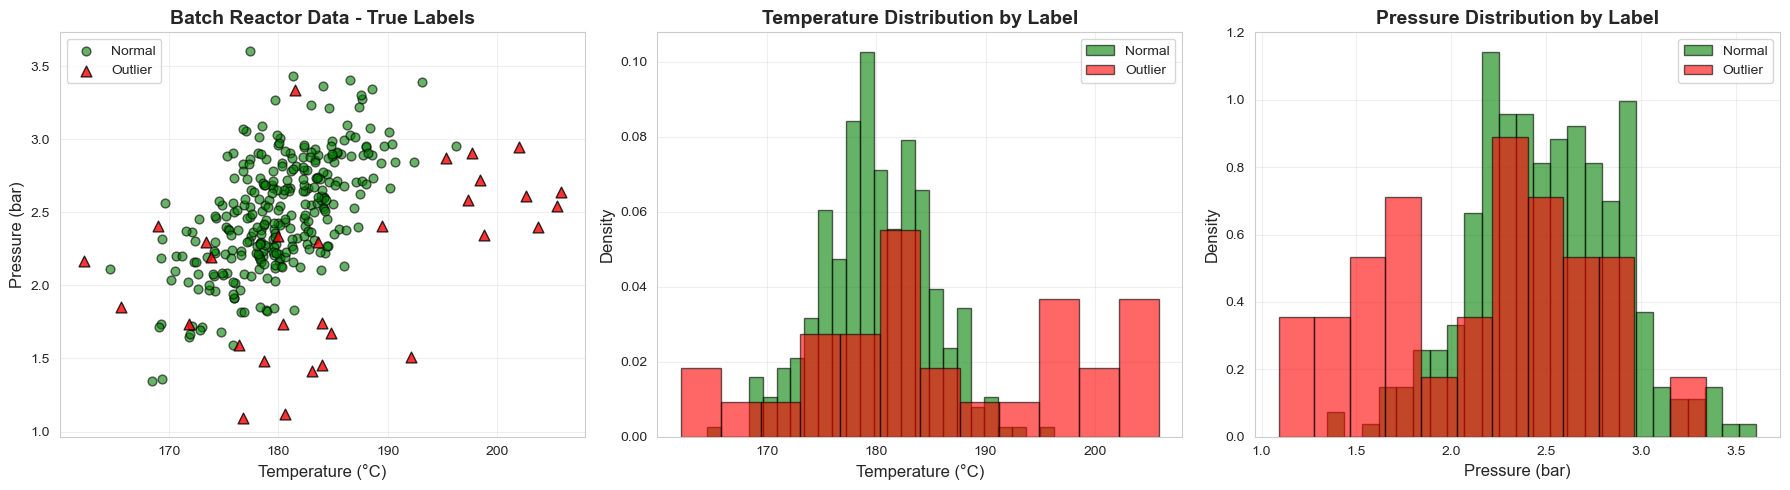

✓ 數據可視化完成，圖表已儲存


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
normal_mask = y_true == 1

# 左圖：真實標籤散布圖
ax1 = axes[0]
ax1.scatter(X[normal_mask, 0], X[normal_mask, 1], c='green', s=40, alpha=0.6, edgecolors='k', label='Normal')
ax1.scatter(X[~normal_mask, 0], X[~normal_mask, 1], c='red', s=60, alpha=0.8, edgecolors='k', marker='^', label='Outlier')
ax1.set_xlabel('Temperature (°C)', fontsize=12)
ax1.set_ylabel('Pressure (bar)', fontsize=12)
ax1.set_title('Batch Reactor Data - True Labels', fontsize=14, fontweight='bold')
ax1.legend(loc='upper left')
ax1.grid(True, alpha=0.3)

# 中圖、右圖：各變數的邊際分布（密度）
for ax, col, unit in [(axes[1], 'Temperature', '°C'), (axes[2], 'Pressure', 'bar')]:
    ax.hist(df.loc[normal_mask, col], bins=25, density=True, alpha=0.6, color='green', edgecolor='k', label='Normal')
    ax.hist(df.loc[~normal_mask, col], bins=12, density=True, alpha=0.6, color='red', edgecolor='k', label='Outlier')
    ax.set_xlabel(f'{col} ({unit})', fontsize=12)
    ax.set_ylabel('Density', fontsize=12)
    ax.set_title(f'{col} Distribution by Label', fontsize=14, fontweight='bold')
    ax.legend(loc='upper right')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / '01_data_visualization.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ 數據可視化完成，圖表已儲存")

---
## 2. 橢圓包絡模型建立與訓練

### 2.1 建立與訓練模型

橢圓包絡屬於**無監督**方法：訓練時不使用標籤，真實標籤僅用於事後評估。`contamination` 僅決定判定閾值（訓練數據馬氏距離平方的百分位數），**不影響** MCD 穩健估計的均值與共變異數。此處先以 $0.1$ 作為基準（接近本案例實際異常比例約 $9.09\%$ ），第 4 節再檢驗不同設定的影響。

In [5]:
CONTAMINATION = 0.1

model = EllipticEnvelope(
    contamination=CONTAMINATION,
    support_fraction=None,  # None: 使用 (n + d + 1) / 2 個點作為 MCD 原始支援集
    random_state=SEED
)
model.fit(X)

# sklearn 的 decision_function = -D^2 - offset_ ，邊界在 D^2 = -offset_
d2_threshold = -model.offset_
d2_chi2 = chi2.ppf(1 - CONTAMINATION, df=X.shape[1])
corr_mcd = model.covariance_[0, 1] / np.sqrt(model.covariance_[0, 0] * model.covariance_[1, 1])

print("✓ 橢圓包絡模型訓練完成")
print(f"\n模型參數:")
print(f"  - Contamination: {model.contamination}")
print(f"  - Support Fraction: {model.support_fraction}")
print(f"\n穩健估計結果:")
print(f"  - 穩健均值 (Location): {model.location_}")
print(f"  - 穩健共變異數矩陣 (Covariance):\n{model.covariance_}")
print(f"  - 溫度-壓力相關係數 (MCD): {corr_mcd:.3f} (設定值 {rho})")
print(f"\n支援集與閾值:")
print(f"  - 原始 MCD 支援點數 (raw_support_): {model.raw_support_.sum()}/{len(X)}")
print(f"  - 重加權後支援點數 (support_): {model.support_.sum()}/{len(X)}")
print(f"  - 決策閾值 D^2 = -offset_: {d2_threshold:.4f}")
print(f"  - 卡方理論閾值 chi2(0.90, df=2): {d2_chi2:.4f} (僅在數據純為高斯且無污染時適用)")

✓ 橢圓包絡模型訓練完成

模型參數:
  - Contamination: 0.1
  - Support Fraction: None

穩健估計結果:
  - 穩健均值 (Location): [180.13156893   2.48403934]
  - 穩健共變異數矩陣 (Covariance):
[[20.05708153  0.97209021]
 [ 0.97209021  0.1452739 ]]
  - 溫度-壓力相關係數 (MCD): 0.569 (設定值 0.6)

支援集與閾值:
  - 原始 MCD 支援點數 (raw_support_): 167/330
  - 重加權後支援點數 (support_): 301/330
  - 決策閾值 D^2 = -offset_: 6.6669
  - 卡方理論閾值 chi2(0.90, df=2): 4.6052 (僅在數據純為高斯且無污染時適用)


### 2.2 模型預測與評估

以「異常」為正類 (positive class)。`confusion_matrix` 的標籤順序為 $[-1, 1]$ ，故矩陣排列為：

| | 預測異常 (-1) | 預測正常 (1) |
|---|---|---|
| **實際異常 (-1)** | TP | FN (漏報) |
| **實際正常 (1)** | FP (誤報) | TN |

In [6]:
y_pred = model.predict(X)
mahal_d2 = model.mahalanobis(X)  # 回傳馬氏距離「平方」 D^2

precision = precision_score(y_true, y_pred, pos_label=-1)
recall = recall_score(y_true, y_pred, pos_label=-1)
f1 = f1_score(y_true, y_pred, pos_label=-1)

# AUC: 以 -decision_function 作為異常分數（越大越異常）
y_binary = (y_true == -1).astype(int)
decision_scores = -model.decision_function(X)
auc = roc_auc_score(y_binary, decision_scores)

cm = confusion_matrix(y_true, y_pred, labels=[-1, 1])
TP, FN = cm[0, 0], cm[0, 1]
FP, TN = cm[1, 0], cm[1, 1]

print("✓ 模型評估完成")
print(f"\n性能指標 (針對異常檢測):")
print(f"  - Precision: {precision:.3f}")
print(f"  - Recall: {recall:.3f}")
print(f"  - F1-Score: {f1:.3f}")
print(f"  - AUC-ROC: {auc:.3f}")

print(f"\n分類報告:")
print(classification_report(y_true, y_pred, target_names=['Outlier', 'Normal']))

print(f"混淆矩陣 (列: 實際 [異常, 正常]；欄: 預測 [異常, 正常]):")
print(cm)
print(f"  - TP: {TP} (異常批次被正確識別)")
print(f"  - FN: {FN} (漏報：異常批次被誤判為正常)")
print(f"  - FP: {FP} (誤報：正常批次被誤判為異常)")
print(f"  - TN: {TN} (正常批次被正確識別)")

print(f"\n💡 實務解讀：")
print(f"   - Precision {precision:.1%}：系統發出警報時，有 {precision:.1%} 的機率是真正的異常")
print(f"   - Recall {recall:.1%}：能找到 {recall:.1%} 的真實異常批次")
print(f"   - 誤報率 (FP / 實際正常)：{FP / (FP + TN):.1%}（{FP}/{FP + TN}）")
print(f"   - 漏報率 (FN / 實際異常)：{FN / (FN + TP):.1%}（{FN}/{FN + TP}）")

✓ 模型評估完成

性能指標 (針對異常檢測):
  - Precision: 0.667
  - Recall: 0.733
  - F1-Score: 0.698
  - AUC-ROC: 0.919

分類報告:
              precision    recall  f1-score   support

     Outlier       0.67      0.73      0.70        30
      Normal       0.97      0.96      0.97       300

    accuracy                           0.94       330
   macro avg       0.82      0.85      0.83       330
weighted avg       0.95      0.94      0.94       330

混淆矩陣 (列: 實際 [異常, 正常]；欄: 預測 [異常, 正常]):
[[ 22   8]
 [ 11 289]]
  - TP: 22 (異常批次被正確識別)
  - FN: 8 (漏報：異常批次被誤判為正常)
  - FP: 11 (誤報：正常批次被誤判為異常)
  - TN: 289 (正常批次被正確識別)

💡 實務解讀：
   - Precision 66.7%：系統發出警報時，有 66.7% 的機率是真正的異常
   - Recall 73.3%：能找到 73.3% 的真實異常批次
   - 誤報率 (FP / 實際正常)：3.7%（11/300）
   - 漏報率 (FN / 實際異常)：26.7%（8/30）


### 2.3 訓練/測試切分驗證

上面的評估是「訓練即評估」(in-sample)。以下以分層抽樣切出 30% 測試集：訓練集（含未標記的異常）訓練模型，再於未見過的測試批次上評估，檢驗結果是否穩定。

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_true, test_size=0.3, stratify=y_true, random_state=SEED
)

model_cv = EllipticEnvelope(contamination=CONTAMINATION, random_state=SEED).fit(X_train)

rows = []
for name, Xs, ys, mdl in [('Train (in-sample)', X_train, y_train, model_cv),
                          ('Test (hold-out)', X_test, y_test, model_cv)]:
    yp = mdl.predict(Xs)
    rows.append({
        'Dataset': name,
        'N': len(ys),
        'Outliers': int(np.sum(ys == -1)),
        'Precision': precision_score(ys, yp, pos_label=-1),
        'Recall': recall_score(ys, yp, pos_label=-1),
        'F1-Score': f1_score(ys, yp, pos_label=-1),
        'AUC': roc_auc_score((ys == -1).astype(int), -mdl.decision_function(Xs))
    })

holdout_df = pd.DataFrame(rows)
print("✓ 切分驗證完成")
print(holdout_df.round(3).to_string(index=False))

# 測試集僅 9 筆異常，單次切分的結果隨機性大，重複 20 次不同切分觀察穩定性
rep = []
for s in range(20):
    Xtr, Xte, ytr, yte = train_test_split(X, y_true, test_size=0.3, stratify=y_true, random_state=s)
    m = EllipticEnvelope(contamination=CONTAMINATION, random_state=SEED).fit(Xtr)
    yp = m.predict(Xte)
    rep.append({
        'Precision': precision_score(yte, yp, pos_label=-1, zero_division=0),
        'Recall': recall_score(yte, yp, pos_label=-1),
        'F1-Score': f1_score(yte, yp, pos_label=-1),
        'AUC': roc_auc_score((yte == -1).astype(int), -m.decision_function(Xte))
    })
rep_df = pd.DataFrame(rep)
print("\n20 次不同切分的測試集表現 (mean ± std):")
for col in rep_df.columns:
    print(f"  - {col}: {rep_df[col].mean():.3f} ± {rep_df[col].std():.3f}  (min {rep_df[col].min():.3f}, max {rep_df[col].max():.3f})")

✓ 切分驗證完成
          Dataset   N  Outliers  Precision  Recall  F1-Score   AUC
Train (in-sample) 231        21      0.739   0.810     0.773 0.958
  Test (hold-out)  99         9      0.800   0.444     0.571 0.826

20 次不同切分的測試集表現 (mean ± std):
  - Precision: 0.670 ± 0.123  (min 0.467, max 0.875)
  - Recall: 0.722 ± 0.122  (min 0.444, max 1.000)
  - F1-Score: 0.686 ± 0.093  (min 0.526, max 0.842)
  - AUC: 0.910 ± 0.058  (min 0.784, max 0.991)


---
## 3. 決策邊界與馬氏距離分析

### 3.1 橢圓決策邊界

決策邊界為 $D_M^2(\mathbf{x}) = c^2$ 的橢圓，其中 $c^2 = -\mathrm{offset\_}$ 。橢圓的主軸方向為共變異數矩陣的特徵向量，半軸長度為 $c\sqrt{\lambda_i}$ 。

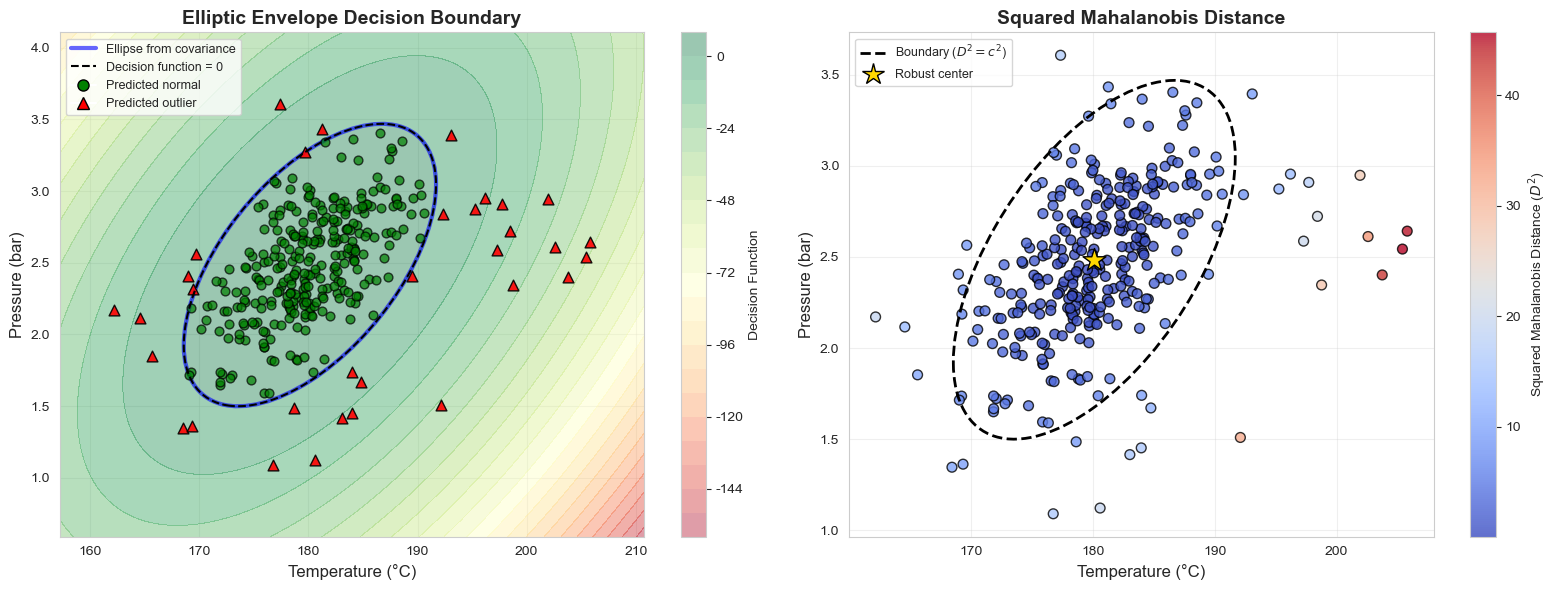

✓ 決策邊界與馬氏距離可視化完成
  - 橢圓半軸長度 c*sqrt(lambda): [ 0.80801267 11.57731426]
  - 被判定為異常的批次數: 33


In [8]:
def cov_ellipse(location, cov, c2, **kwargs):
    """回傳滿足 (x - mu)^T cov^-1 (x - mu) = c2 的橢圓 patch"""
    vals, vecs = np.linalg.eigh(cov)
    angle = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))
    width, height = 2 * np.sqrt(c2 * vals)
    return Ellipse(location, width, height, angle=angle, fill=False, **kwargs)


fig, axes = plt.subplots(1, 2, figsize=(16, 6))

xx, yy = np.meshgrid(
    np.linspace(X[:, 0].min() - 5, X[:, 0].max() + 5, 200),
    np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 200)
)
Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
pred_normal = y_pred == 1

# 左圖：決策邊界與預測結果
ax1 = axes[0]
cf = ax1.contourf(xx, yy, Z, levels=20, cmap='RdYlGn', alpha=0.4)
ax1.contour(xx, yy, Z, levels=[0], colors='black', linewidths=1.5, linestyles='--')
ax1.add_patch(cov_ellipse(model.location_, model.covariance_, d2_threshold, edgecolor='blue', linewidth=3, alpha=0.6))
ax1.scatter(X[pred_normal, 0], X[pred_normal, 1], c='green', s=40, alpha=0.7, edgecolors='k')
ax1.scatter(X[~pred_normal, 0], X[~pred_normal, 1], c='red', s=60, alpha=0.9, edgecolors='k', marker='^')
ax1.set_xlabel('Temperature (°C)', fontsize=12)
ax1.set_ylabel('Pressure (bar)', fontsize=12)
ax1.set_title('Elliptic Envelope Decision Boundary', fontsize=14, fontweight='bold')
ax1.legend(handles=[
    Line2D([0], [0], color='blue', lw=3, alpha=0.6, label='Ellipse from covariance'),
    Line2D([0], [0], color='black', lw=1.5, ls='--', label='Decision function = 0'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='green', markeredgecolor='k', ms=8, label='Predicted normal'),
    Line2D([0], [0], marker='^', color='w', markerfacecolor='red', markeredgecolor='k', ms=9, label='Predicted outlier'),
], loc='upper left', fontsize=9)
ax1.grid(True, alpha=0.3)
plt.colorbar(cf, ax=ax1, label='Decision Function')

# 右圖：馬氏距離平方
ax2 = axes[1]
sc = ax2.scatter(X[:, 0], X[:, 1], c=mahal_d2, cmap='coolwarm', s=50, alpha=0.8, edgecolors='k')
ax2.add_patch(cov_ellipse(model.location_, model.covariance_, d2_threshold, edgecolor='black', linewidth=2, linestyle='--'))
ax2.scatter(*model.location_, marker='*', s=300, c='gold', edgecolors='k', zorder=5)
ax2.set_xlabel('Temperature (°C)', fontsize=12)
ax2.set_ylabel('Pressure (bar)', fontsize=12)
ax2.set_title('Squared Mahalanobis Distance', fontsize=14, fontweight='bold')
ax2.legend(handles=[
    Line2D([0], [0], color='black', lw=2, ls='--', label='Boundary ($D^2 = c^2$)'),
    Line2D([0], [0], marker='*', color='w', markerfacecolor='gold', markeredgecolor='k', ms=16, label='Robust center'),
], loc='upper left', fontsize=9)
ax2.grid(True, alpha=0.3)
plt.colorbar(sc, ax=ax2, label='Squared Mahalanobis Distance ($D^2$)')

plt.tight_layout()
plt.savefig(FIG_DIR / '02_decision_boundary_and_mahalanobis.png', dpi=300, bbox_inches='tight')
plt.show()

vals, _ = np.linalg.eigh(model.covariance_)
print("✓ 決策邊界與馬氏距離可視化完成")
print(f"  - 橢圓半軸長度 c*sqrt(lambda): {np.sqrt(d2_threshold * vals)}")
print(f"  - 被判定為異常的批次數: {np.sum(~pred_normal)}")

### 3.2 MCD 穩健估計 vs. 經驗共變異數

橢圓包絡使用 MCD 估計均值與共變異數。為了驗證其穩健性，將其與傳統**經驗共變異數** (`EmpiricalCovariance`) 在同一份含 $9.09\%$ 異常的數據上比較，並以理論參數（建立數據時使用的設定值）作為基準。

✓ 共變異數估計比較
            Estimator  Mean_T  Mean_P  Var_T  Var_P  Corr
True (normal batches) 180.000   2.500 25.000  0.160 0.600
            Empirical 180.589   2.466 38.173  0.175 0.448
         MCD (robust) 180.132   2.484 20.057  0.145 0.569


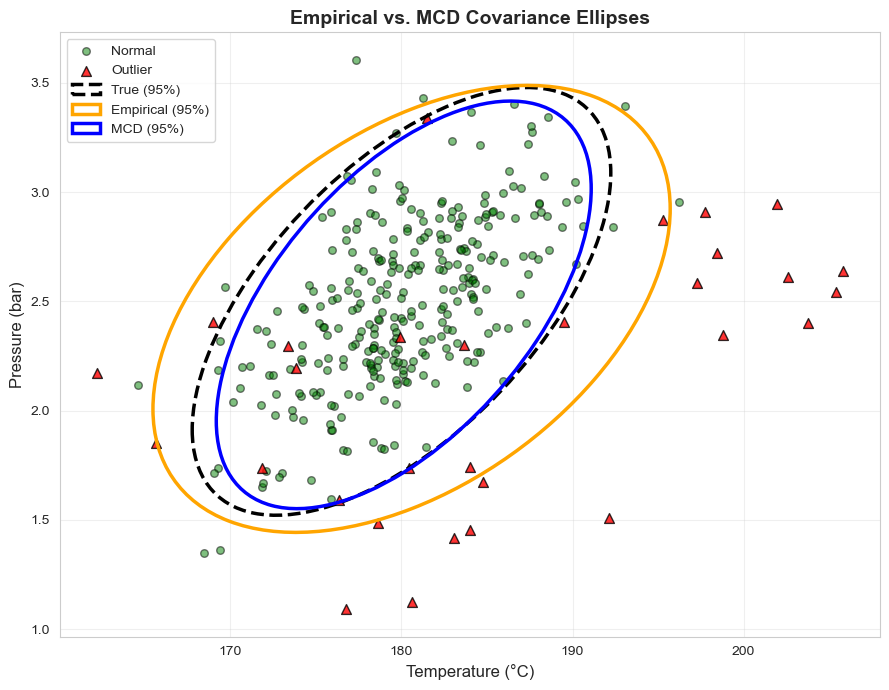


橢圓面積 (true / empirical / MCD): 30.12 / 43.46 / 26.41


In [9]:
emp = EmpiricalCovariance().fit(X)
mcd = MinCovDet(random_state=SEED).fit(X)
true_cov = np.array(cov_normal)


def to_row(name, loc, cov):
    return {
        'Estimator': name,
        'Mean_T': loc[0], 'Mean_P': loc[1],
        'Var_T': cov[0, 0], 'Var_P': cov[1, 1],
        'Corr': cov[0, 1] / np.sqrt(cov[0, 0] * cov[1, 1])
    }


cmp_df = pd.DataFrame([
    to_row('True (normal batches)', mean_normal, true_cov),
    to_row('Empirical', emp.location_, emp.covariance_),
    to_row('MCD (robust)', mcd.location_, mcd.covariance_),
])
print("✓ 共變異數估計比較")
print(cmp_df.round(3).to_string(index=False))

# 以 95% 等密度橢圓比較 (c^2 = chi2 0.95, df=2)
c2_95 = chi2.ppf(0.95, df=2)
fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(X[normal_mask, 0], X[normal_mask, 1], c='green', s=30, alpha=0.5, edgecolors='k', label='Normal')
ax.scatter(X[~normal_mask, 0], X[~normal_mask, 1], c='red', s=50, alpha=0.8, edgecolors='k', marker='^', label='Outlier')
ax.add_patch(cov_ellipse(mean_normal, true_cov, c2_95, edgecolor='black', linewidth=2.5, linestyle='--', label='True (95%)'))
ax.add_patch(cov_ellipse(emp.location_, emp.covariance_, c2_95, edgecolor='orange', linewidth=2.5, label='Empirical (95%)'))
ax.add_patch(cov_ellipse(mcd.location_, mcd.covariance_, c2_95, edgecolor='blue', linewidth=2.5, label='MCD (95%)'))
ax.set_xlabel('Temperature (°C)', fontsize=12)
ax.set_ylabel('Pressure (bar)', fontsize=12)
ax.set_title('Empirical vs. MCD Covariance Ellipses', fontsize=14, fontweight='bold')
ax.legend(loc='upper left', fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / '03_mcd_vs_empirical.png', dpi=300, bbox_inches='tight')
plt.show()

area = lambda cov: np.pi * c2_95 * np.sqrt(np.linalg.det(cov))
print(f"\n橢圓面積 (true / empirical / MCD): {area(true_cov):.2f} / {area(emp.covariance_):.2f} / {area(mcd.covariance_):.2f}")

---
## 4. 超參數調整

`contamination` 只改變判定閾值，不改變 MCD 估計的均值與共變異數，因此馬氏距離排序與 AUC 不隨之改變；提高 `contamination` 會讓橢圓邊界收縮，更多批次被判為異常（Recall 上升、Precision 下降）。

> 以下以真實標籤計算 Precision、Recall、F1 僅供教學說明。實務上通常沒有異常標籤，`contamination` 應根據歷史異常率、誤報與漏報成本設定。

✓ Contamination 參數影響分析完成
 Contamination  Precision  Recall  F1-Score   AUC  Detected_Outliers  False_Alarms  D2_Threshold
          0.01      1.000   0.133     0.235 0.919                  4             0        33.756
          0.05      0.882   0.500     0.638 0.919                 17             2        13.736
          0.10      0.667   0.733     0.698 0.919                 33            11         6.667
          0.15      0.500   0.833     0.625 0.919                 50            25         5.272
          0.20      0.394   0.867     0.542 0.919                 66            40         4.428
          0.25      0.313   0.867     0.460 0.919                 83            57         3.598


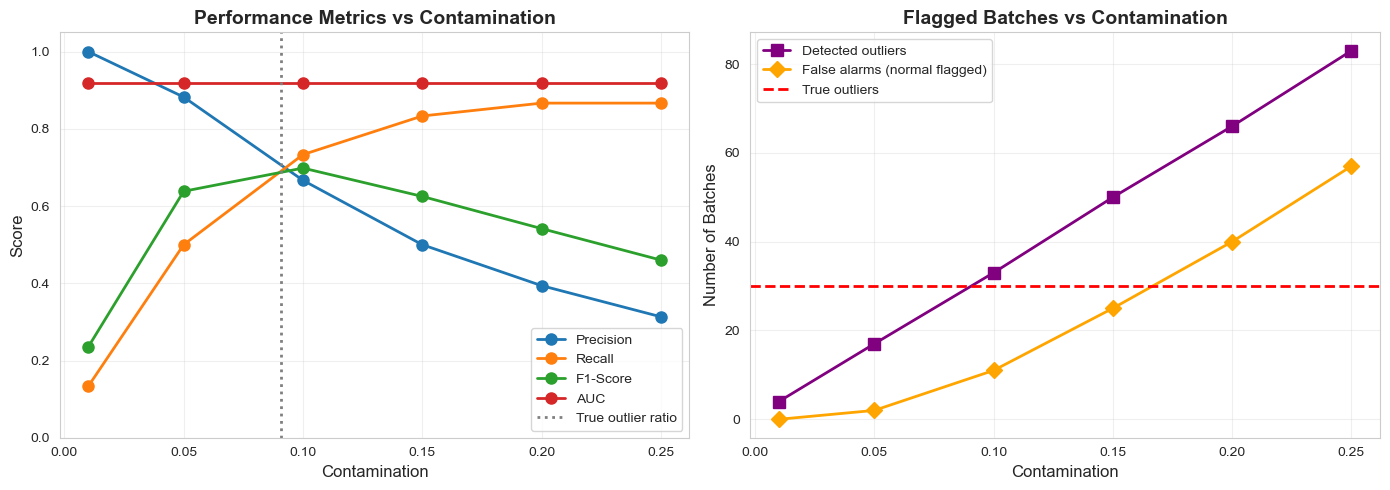


F1-Score 最高的 Contamination: 0.1 (F1 = 0.698)


In [10]:
contamination_values = [0.01, 0.05, 0.1, 0.15, 0.2, 0.25]
results = []

for cont in contamination_values:
    m = EllipticEnvelope(contamination=cont, random_state=SEED).fit(X)
    yp = m.predict(X)
    cm_t = confusion_matrix(y_true, yp, labels=[-1, 1])
    results.append({
        'Contamination': cont,
        'Precision': precision_score(y_true, yp, pos_label=-1, zero_division=0),
        'Recall': recall_score(y_true, yp, pos_label=-1),
        'F1-Score': f1_score(y_true, yp, pos_label=-1),
        'AUC': roc_auc_score(y_binary, -m.decision_function(X)),
        'Detected_Outliers': int(np.sum(yp == -1)),
        'False_Alarms': int(cm_t[1, 0]),
        'D2_Threshold': -m.offset_
    })

results_df = pd.DataFrame(results)
print("✓ Contamination 參數影響分析完成")
print(results_df.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax1 = axes[0]
results_df.plot(x='Contamination', y=['Precision', 'Recall', 'F1-Score', 'AUC'],
                ax=ax1, marker='o', linewidth=2, markersize=8)
ax1.axvline(x=n_outliers / len(X), color='gray', linestyle=':', linewidth=2, label='True outlier ratio')
ax1.set_xlabel('Contamination', fontsize=12)
ax1.set_ylabel('Score', fontsize=12)
ax1.set_title('Performance Metrics vs Contamination', fontsize=14, fontweight='bold')
ax1.legend(loc='best')
ax1.grid(True, alpha=0.3)
ax1.set_ylim([0, 1.05])

ax2 = axes[1]
ax2.plot(results_df['Contamination'], results_df['Detected_Outliers'],
         marker='s', linewidth=2, markersize=8, color='purple', label='Detected outliers')
ax2.plot(results_df['Contamination'], results_df['False_Alarms'],
         marker='D', linewidth=2, markersize=8, color='orange', label='False alarms (normal flagged)')
ax2.axhline(y=n_outliers, color='red', linestyle='--', linewidth=2, label='True outliers')
ax2.set_xlabel('Contamination', fontsize=12)
ax2.set_ylabel('Number of Batches', fontsize=12)
ax2.set_title('Flagged Batches vs Contamination', fontsize=14, fontweight='bold')
ax2.legend(loc='best')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / '04_contamination_tuning.png', dpi=300, bbox_inches='tight')
plt.show()

best_idx = results_df['F1-Score'].idxmax()
print(f"\nF1-Score 最高的 Contamination: {results_df.loc[best_idx, 'Contamination']} (F1 = {results_df.loc[best_idx, 'F1-Score']:.3f})")

---
## 5. ROC 曲線與混淆矩陣

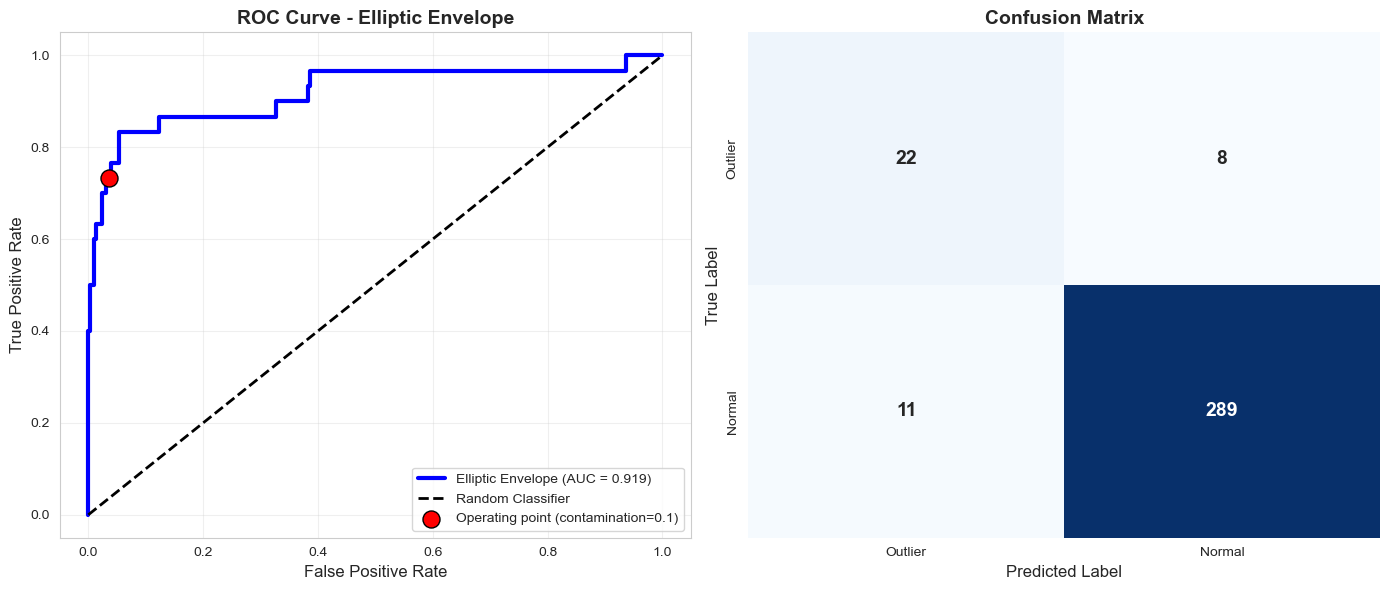

✓ ROC 曲線與混淆矩陣可視化完成
  - AUC = 0.919
  - 工作點: FPR = 0.037, TPR = 0.733


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 左圖：ROC 曲線（以異常為正類）
ax1 = axes[0]
fpr, tpr, thresholds = roc_curve(y_binary, decision_scores)
op_fpr, op_tpr = FP / (FP + TN), TP / (TP + FN)

ax1.plot(fpr, tpr, linewidth=3, color='blue', label=f'Elliptic Envelope (AUC = {auc:.3f})')
ax1.plot([0, 1], [0, 1], 'k--', linewidth=2, label='Random Classifier')
ax1.scatter([op_fpr], [op_tpr], s=150, c='red', edgecolors='k', zorder=5,
            label=f'Operating point (contamination={CONTAMINATION})')
ax1.set_xlabel('False Positive Rate', fontsize=12)
ax1.set_ylabel('True Positive Rate', fontsize=12)
ax1.set_title('ROC Curve - Elliptic Envelope', fontsize=14, fontweight='bold')
ax1.legend(loc='lower right', fontsize=10)
ax1.grid(True, alpha=0.3)

# 右圖：混淆矩陣
ax2 = axes[1]
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax2,
            xticklabels=['Outlier', 'Normal'], yticklabels=['Outlier', 'Normal'],
            annot_kws={'size': 14, 'weight': 'bold'})
ax2.set_xlabel('Predicted Label', fontsize=12)
ax2.set_ylabel('True Label', fontsize=12)
ax2.set_title('Confusion Matrix', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig(FIG_DIR / '05_roc_and_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ ROC 曲線與混淆矩陣可視化完成")
print(f"  - AUC = {auc:.3f}")
print(f"  - 工作點: FPR = {op_fpr:.3f}, TPR = {op_tpr:.3f}")

---
## 6. 與其他方法的比較

橢圓包絡對特徵的線性轉換（平移、縮放、旋轉）具不變性；One-Class SVM 與 LOF 基於距離或核函數，必須先標準化，否則溫度（約 180）會主導壓力（約 2.5）。Isolation Forest 對單一特徵的縮放不敏感，直接使用原始數據。除 Precision、Recall、F1 外，同時報告與閾值無關的 AUC。

✓ 方法比較完成
           Method  Precision  Recall  F1-Score   AUC  Detected
Elliptic Envelope      0.667   0.733     0.698 0.919        33
 Isolation Forest      0.576   0.633     0.603 0.902        33
    One-Class SVM      0.417   0.500     0.455 0.653        36
              LOF      0.636   0.700     0.667 0.895        33


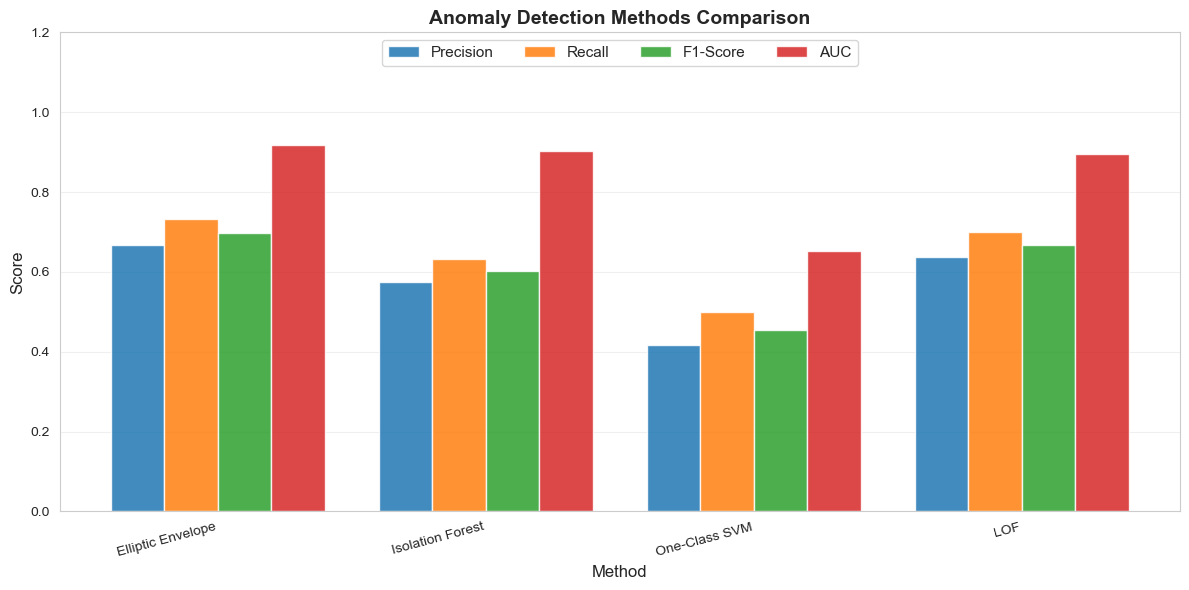


F1-Score 最高的方法: Elliptic Envelope (F1 = 0.698)


In [12]:
X_scaled = StandardScaler().fit_transform(X)

methods = {
    'Elliptic Envelope': (EllipticEnvelope(contamination=CONTAMINATION, random_state=SEED), X),
    'Isolation Forest': (IsolationForest(contamination=CONTAMINATION, random_state=SEED), X),
    'One-Class SVM': (OneClassSVM(nu=CONTAMINATION, kernel='rbf', gamma='scale'), X_scaled),
    'LOF': (LocalOutlierFactor(n_neighbors=20, contamination=CONTAMINATION), X_scaled),
}

comparison_results = []
for name, (est, data) in methods.items():
    if name == 'LOF':
        yp = est.fit_predict(data)
        score = -est.negative_outlier_factor_
    else:
        est.fit(data)
        yp = est.predict(data)
        score = -est.decision_function(data)

    comparison_results.append({
        'Method': name,
        'Precision': precision_score(y_true, yp, pos_label=-1, zero_division=0),
        'Recall': recall_score(y_true, yp, pos_label=-1),
        'F1-Score': f1_score(y_true, yp, pos_label=-1),
        'AUC': roc_auc_score(y_binary, score),
        'Detected': int(np.sum(yp == -1))
    })

comparison_df = pd.DataFrame(comparison_results)
print("✓ 方法比較完成")
print(comparison_df.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 6))
x_pos = np.arange(len(comparison_df))
width = 0.2
for i, metric in enumerate(['Precision', 'Recall', 'F1-Score', 'AUC']):
    ax.bar(x_pos + (i - 1.5) * width, comparison_df[metric], width, label=metric, alpha=0.85)

ax.set_xlabel('Method', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Anomaly Detection Methods Comparison', fontsize=14, fontweight='bold')
ax.set_xticks(x_pos)
ax.set_xticklabels(comparison_df['Method'], rotation=15, ha='right')
ax.legend(loc='upper center', ncol=4, fontsize=11)
ax.grid(True, alpha=0.3, axis='y')
ax.grid(False, axis='x')
ax.set_ylim([0, 1.2])

plt.tight_layout()
plt.savefig(FIG_DIR / '06_methods_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

best_method = comparison_df.loc[comparison_df['F1-Score'].idxmax(), 'Method']
print(f"\nF1-Score 最高的方法: {best_method} (F1 = {comparison_df['F1-Score'].max():.3f})")

---
## 7. 實務應用：製程監控儀表板

模擬最近 20 個新批次，其中人工植入 2 個異常批次（第 6 批：高溫；第 16 批：低壓），使用已訓練的模型即時判定。

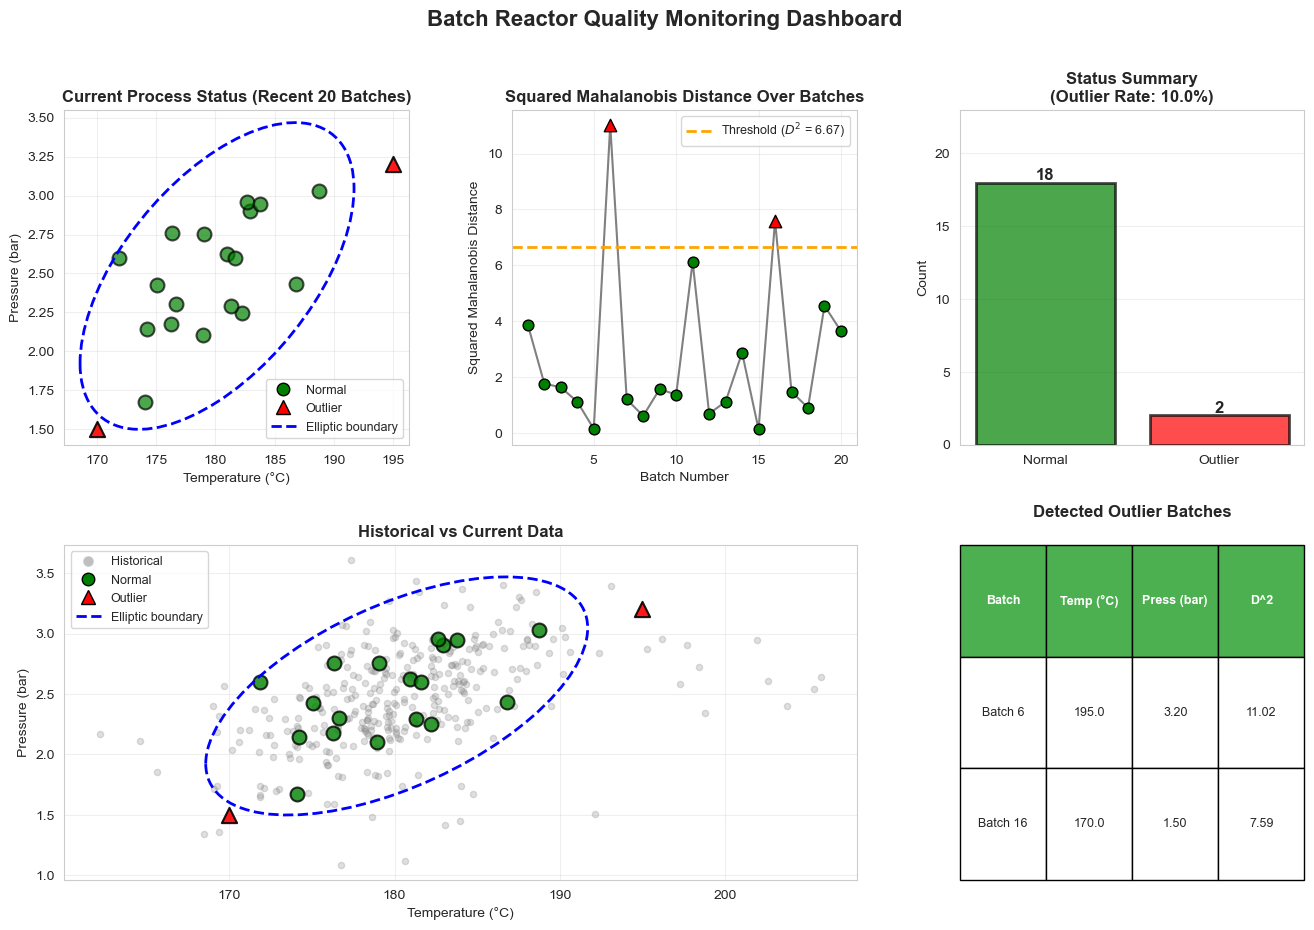

✓ 製程監控儀表板完成

監控摘要:
  - 最近批次數: 20
  - 異常批次數: 2
  - 異常批次編號: [ 6 16]
  - 異常比例: 10.0%
  - 植入異常批次 (6, 16) 的 D^2: 11.02, 7.59 (閾值 6.67)

💡 實務建議：
   - 異常批次應立即進行根因分析
   - 檢查是否需要調整製程參數或設備維護
   - 建立異常事件記錄，累積經驗知識庫


In [13]:
np.random.seed(100)
n_recent = 20
X_recent = np.random.multivariate_normal(mean_normal, cov_normal, n_recent)
X_recent[5] = [195, 3.2]   # 第 6 批
X_recent[15] = [170, 1.5]  # 第 16 批

y_pred_recent = model.predict(X_recent)
d2_recent = model.mahalanobis(X_recent)
recent_out = y_pred_recent == -1
outlier_indices = np.where(recent_out)[0]

fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(2, 3, hspace=0.3, wspace=0.3)
legend_handles = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='green', markeredgecolor='k', ms=9, label='Normal'),
    Line2D([0], [0], marker='^', color='w', markerfacecolor='red', markeredgecolor='k', ms=10, label='Outlier'),
    Line2D([0], [0], color='blue', lw=2, ls='--', label='Elliptic boundary'),
]

# 1. 近期批次與橢圓邊界（左上）
ax1 = fig.add_subplot(gs[0, 0])
ax1.scatter(X_recent[~recent_out, 0], X_recent[~recent_out, 1], c='green', s=100, alpha=0.7, edgecolors='k', linewidth=1.5)
ax1.scatter(X_recent[recent_out, 0], X_recent[recent_out, 1], c='red', s=120, alpha=0.9, edgecolors='k', linewidth=1.5, marker='^')
ax1.add_patch(cov_ellipse(model.location_, model.covariance_, d2_threshold, edgecolor='blue', linewidth=2, linestyle='--'))
ax1.set_xlabel('Temperature (°C)', fontsize=10)
ax1.set_ylabel('Pressure (bar)', fontsize=10)
ax1.set_title('Current Process Status (Recent 20 Batches)', fontsize=12, fontweight='bold')
ax1.legend(handles=legend_handles, loc='lower right', fontsize=9)
ax1.grid(True, alpha=0.3)

# 2. 馬氏距離平方時間序列（中上）
ax2 = fig.add_subplot(gs[0, 1])
batch_no = np.arange(1, n_recent + 1)
ax2.plot(batch_no, d2_recent, color='gray', linewidth=1.5, zorder=1)
ax2.scatter(batch_no[~recent_out], d2_recent[~recent_out], c='green', s=60, edgecolors='k', zorder=2)
ax2.scatter(batch_no[recent_out], d2_recent[recent_out], c='red', s=80, edgecolors='k', marker='^', zorder=2)
ax2.axhline(y=d2_threshold, color='orange', linestyle='--', linewidth=2, label=f'Threshold ($D^2$ = {d2_threshold:.2f})')
ax2.set_xlabel('Batch Number', fontsize=10)
ax2.set_ylabel('Squared Mahalanobis Distance', fontsize=10)
ax2.set_title('Squared Mahalanobis Distance Over Batches', fontsize=12, fontweight='bold')
ax2.legend(loc='upper right', fontsize=9)
ax2.grid(True, alpha=0.3)

# 3. 異常統計（右上）
ax3 = fig.add_subplot(gs[0, 2])
n_out_recent = int(recent_out.sum())
bars = ax3.bar(['Normal', 'Outlier'], [n_recent - n_out_recent, n_out_recent],
               color=['green', 'red'], alpha=0.7, edgecolor='k', linewidth=2)
ax3.set_ylim(0, n_recent * 1.15)
ax3.set_ylabel('Count', fontsize=10)
ax3.set_title(f'Status Summary\n(Outlier Rate: {n_out_recent / n_recent:.1%})', fontsize=12, fontweight='bold')
ax3.grid(True, alpha=0.3, axis='y')
ax3.grid(False, axis='x')
for bar in bars:
    ax3.text(bar.get_x() + bar.get_width() / 2., bar.get_height(), f'{int(bar.get_height())}',
             ha='center', va='bottom', fontsize=12, fontweight='bold')

# 4. 歷史數據 vs 近期批次（左下，跨兩格）
ax4 = fig.add_subplot(gs[1, :2])
ax4.scatter(X[:, 0], X[:, 1], c='gray', s=20, alpha=0.25)
ax4.scatter(X_recent[~recent_out, 0], X_recent[~recent_out, 1], c='green', s=100, alpha=0.8, edgecolors='k', linewidth=1.5)
ax4.scatter(X_recent[recent_out, 0], X_recent[recent_out, 1], c='red', s=120, alpha=0.9, edgecolors='k', linewidth=1.5, marker='^')
ax4.add_patch(cov_ellipse(model.location_, model.covariance_, d2_threshold, edgecolor='blue', linewidth=2, linestyle='--'))
ax4.set_xlabel('Temperature (°C)', fontsize=10)
ax4.set_ylabel('Pressure (bar)', fontsize=10)
ax4.set_title('Historical vs Current Data', fontsize=12, fontweight='bold')
ax4.legend(handles=[Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', ms=8, alpha=0.5, label='Historical')] + legend_handles,
           loc='upper left', fontsize=9)
ax4.grid(True, alpha=0.3)

# 5. 異常批次列表（右下）
ax5 = fig.add_subplot(gs[1, 2])
ax5.axis('off')
if len(outlier_indices) > 0:
    table_data = [[f'Batch {i + 1}', f'{X_recent[i, 0]:.1f}', f'{X_recent[i, 1]:.2f}', f'{d2_recent[i]:.2f}']
                  for i in outlier_indices]
    table = ax5.table(cellText=table_data, colLabels=['Batch', 'Temp (°C)', 'Press (bar)', 'D^2'],
                      cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1, 2)
    for j in range(4):
        table[(0, j)].set_facecolor('#4CAF50')
        table[(0, j)].set_text_props(weight='bold', color='white')
else:
    ax5.text(0.5, 0.5, 'No Outliers Detected', ha='center', va='center', fontsize=14, fontweight='bold')
ax5.set_title('Detected Outlier Batches', fontsize=12, fontweight='bold', pad=20)

plt.suptitle('Batch Reactor Quality Monitoring Dashboard', fontsize=16, fontweight='bold', y=0.98)
plt.savefig(FIG_DIR / '07_monitoring_dashboard.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ 製程監控儀表板完成")
print(f"\n監控摘要:")
print(f"  - 最近批次數: {n_recent}")
print(f"  - 異常批次數: {n_out_recent}")
print(f"  - 異常批次編號: {outlier_indices + 1}")
print(f"  - 異常比例: {n_out_recent / n_recent:.1%}")
print(f"  - 植入異常批次 (6, 16) 的 D^2: {d2_recent[5]:.2f}, {d2_recent[15]:.2f} (閾值 {d2_threshold:.2f})")
print(f"\n💡 實務建議：")
print(f"   - 異常批次應立即進行根因分析")
print(f"   - 檢查是否需要調整製程參數或設備維護")
print(f"   - 建立異常事件記錄，累積經驗知識庫")

---
## 8. 模型儲存

In [14]:
joblib.dump(model, MODEL_DIR / 'elliptic_envelope_model.pkl')

loaded = joblib.load(MODEL_DIR / 'elliptic_envelope_model.pkl')
assert np.array_equal(loaded.predict(X), model.predict(X))
print(f"✓ 模型已儲存並驗證可重新載入: {MODEL_DIR / 'elliptic_envelope_model.pkl'}")

✓ 模型已儲存並驗證可重新載入: d:\MyGit\ChemE-3590\Part_2\Unit07\outputs\P2_Unit07_Elliptic_Envelope\models\elliptic_envelope_model.pkl


---
## 9. 總結與建議

### 9.1 核心學習重點

1. **理論基礎**
   - 橢圓包絡假設正常數據服從多變量高斯分布，以馬氏距離平方 $D_M^2$ 衡量異常程度
   - MCD 提供穩健的均值與共變異數估計：在含 9.09% 異常的數據上，經驗共變異數的溫度變異數被拉高到 38.17（設定值 25），橢圓面積為 43.46；MCD 估計為 20.06，橢圓面積 26.41，較接近理論值 30.12
   - 決策邊界是 $D_M^2 = -\mathrm{offset\_}$ 的橢圓（本例閾值 6.67），可由共變異數的特徵分解直接畫出

2. **實作結果**（`contamination=0.1`，in-sample）
   - Precision 0.667、Recall 0.733、F1 0.698、AUC 0.919；混淆矩陣為 TP=22、FN=8、FP=11、TN=289
   - 切分驗證：單次切分的測試集僅 9 個異常，Recall 0.444 屬隨機波動；20 次不同切分的測試集平均 F1 為 0.686 ± 0.093、AUC 為 0.910 ± 0.058，與 in-sample 結果一致
   - `contamination` 只移動閾值，AUC 恆為 0.919；調高 `contamination` 使 Recall 由 0.133 升至 0.867，Precision 由 1.000 降至 0.313
   - 本案例 F1 在 `contamination=0.1` 最高，與實際異常比例 9.09% 相近

3. **方法比較**（同一份數據，`contamination=0.1`）
   - 橢圓包絡 F1=0.698、AUC=0.919 最高，其次為 LOF（F1=0.667、AUC=0.895）與 Isolation Forest（F1=0.603、AUC=0.902）；One-Class SVM 最低（F1=0.455、AUC=0.653）
   - 本案例的正常數據由高斯分布生成，完全符合橢圓包絡的假設，因此其表現領先。若數據偏離高斯分布，結論可能不同
   - 單一數據集、單一種子的結果不能直接推廣到其他製程

4. **化工應用**
   - 近期 20 批監控中，植入的第 6 批（ $D^2 = 11.02$ ）與第 16 批（ $D^2 = 7.59$ ）皆被偵測，閾值為 6.67；第 11 批 $D^2$ 為 6.13，接近但未超過閾值
   - 第 16 批（170 °C、1.50 bar）的溫度與壓力分別約為 -2σ 與 -2.5σ，單變數 3σ 控制圖不會報警，但兩者組合與溫度-壓力的正相關關係不符，這是馬氏距離相較於單變數控制圖的優勢

### 9.2 方法選擇建議

**使用橢圓包絡的場景**：
- ✅ 數據接近多變量高斯分布
- ✅ 變數間有相關性
- ✅ 需要可解釋的決策邊界
- ✅ 中等維度數據 ( $d < 20$ ) 且樣本數充足

**考慮其他方法的場景**：
- ❌ 數據明顯非高斯分布 → 先轉換（如 Yeo-Johnson）或使用 Isolation Forest
- ❌ 多模態數據 → 使用 LOF 或分模式建模
- ❌ 高維數據 → 使用 Isolation Forest 或先降維
- ❌ 複雜非線性邊界 → 使用 One-Class SVM (RBF kernel)，且必須標準化

### 9.3 實務應用建議

1. **參數設定**：`contamination` 應依歷史異常率與誤報、漏報成本決定；實務上沒有標籤，不應照本 Notebook 以標籤挑選
2. **評估方式**：異常樣本少時，單次切分的 Precision、Recall 不穩定，應重複切分或使用 AUC 等與閾值無關的指標
3. **模型維護**：製程穩態下建模，定期以新數據重新訓練，並監控誤報與漏報情況
4. **系統整合**：結合物理約束與領域知識，建立多層次警報（如以不同 $D^2$ 閾值分級）

### 9.4 延伸學習

- 探索 `sklearn.covariance` 的其他估計方法（如 `GraphicalLasso`、`LedoitWolf`）
- 學習 Hotelling's $T^2$ 統計製程控制
- 研究動態製程的異常檢測（時間序列方法）

---

**練習題**：

1. 將相關係數 `rho` 改為 0.0 與 0.9，觀察橢圓形狀與偵測效能的變化
2. 將特徵擴充為 5 個以上變數，觀察樣本數與維度比對 MCD 估計的影響
3. 將正常數據改為偏態分布（如對數常態），比較轉換前後的偵測效能
4. 比較 `support_fraction` 取 0.6、0.8、0.95 對估計結果與 AUC 的影響

---

**Notebook 結束**